In [5]:
# common cell for PS 6-10
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense

In [3]:
train = pd.read_csv("sign_mnist_train.csv")
test = pd.read_csv("sign_mnist_test.csv")

print("Training shape:", train.shape)
print("Testing shape:", test.shape)

Training shape: (27455, 785)
Testing shape: (7172, 785)


In [4]:
X_train = train.drop("label", axis=1).values
y_train = train["label"].values

X_test = test.drop("label", axis=1).values
y_test = test["label"].values

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (27455, 784)
X_test: (7172, 784)


In [6]:
X_train = X_train / 255.0
X_test = X_test / 255.0

print("Pixel values normalized")

Pixel values normalized


In [7]:
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

print("New training shape:", X_train.shape)
print("New testing shape:", X_test.shape)

New training shape: (27455, 28, 28, 1)
New testing shape: (7172, 28, 28, 1)


In [17]:
print("Number of classes:", len(np.unique(y_train)))
print("Labels:", np.unique(y_train))

Number of classes: 24
Labels: [ 0  1  2  3  4  5  6  7  8 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24]


In [21]:
model = Sequential([
    Conv2D(32, (3, 3), activation="relu",
           input_shape=(28, 28, 1)),

    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu"),

    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(128, activation="relu"),

    Dense(25, activation="softmax")
])

model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_8 (Conv2D)                    │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_8 (MaxPooling2D)       │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_9 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_9 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_4 (Flatten)                  │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 128)                 │         204,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ (None, 25)                  │           3,225 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 226,969 (886.60 KB)

 Trainable params: 226,969 (886.60 KB)

 Non-trainable params: 0 (0.00 B)

In [22]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [23]:
history = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=32
)

Epoch 1/5
858/858 ━━━━━━━━━━━━━━━━━━━━ 22s 24ms/step - accuracy: 0.7587 - loss: 0.8167
Epoch 2/5
858/858 ━━━━━━━━━━━━━━━━━━━━ 20s 23ms/step - accuracy: 0.9923 - loss: 0.0461
Epoch 3/5
858/858 ━━━━━━━━━━━━━━━━━━━━ 18s 21ms/step - accuracy: 0.9998 - loss: 0.0060
Epoch 4/5
858/858 ━━━━━━━━━━━━━━━━━━━━ 18s 21ms/step - accuracy: 0.9924 - loss: 0.0257
Epoch 5/5
858/858 ━━━━━━━━━━━━━━━━━━━━ 19s 22ms/step - accuracy: 0.9999 - loss: 0.0011


In [24]:
#common for 6,8,9,10
loss, accuracy = model.evaluate(X_test, y_test)

print("Testing Accuracy:", accuracy)
print("Testing Accuracy (%):", accuracy * 100)

225/225 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.9288 - loss: 0.3424
Testing Accuracy: 0.9287506937980652
Testing Accuracy (%): 92.87506937980652


In [25]:
#for chit 7 output
predictions = model.predict(X_test)

for i in range(5):

    actual = y_test[i]
    predicted = np.argmax(predictions[i])

    print("Image", i + 1)
    print("Actual label:", actual)
    print("Predicted label:", predicted)
    print()

225/225 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step
Image 1
Actual label: 6
Predicted label: 6

Image 2
Actual label: 5
Predicted label: 5

Image 3
Actual label: 10
Predicted label: 10

Image 4
Actual label: 0
Predicted label: 0

Image 5
Actual label: 3
Predicted label: 3



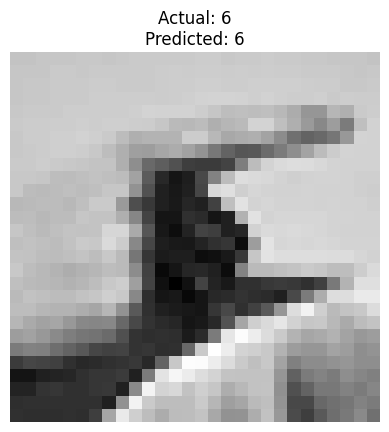

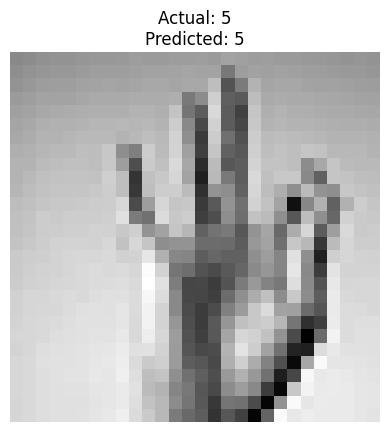

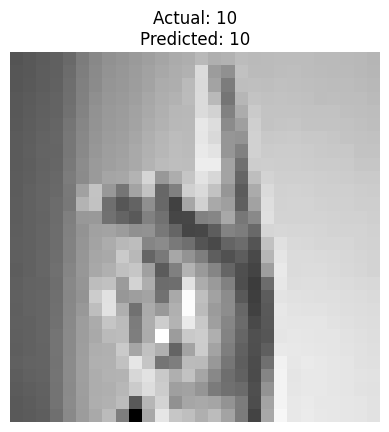

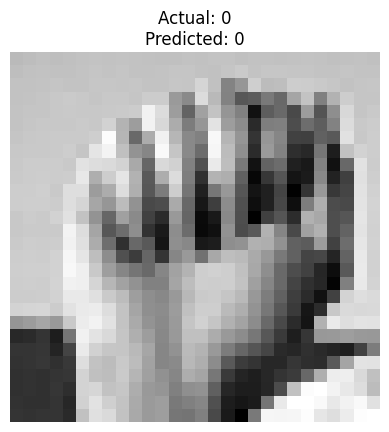

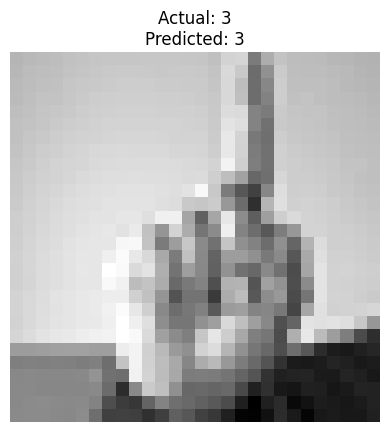

In [26]:
for i in range(5):

    predicted = np.argmax(predictions[i])

    plt.imshow(X_test[i].reshape(28, 28), cmap="gray")

    plt.title(
        f"Actual: {y_test[i]}\n"
        f"Predicted: {predicted}"
    )

    plt.axis("off")
    plt.show()

In [ ]:
#for Chit 8 change history
history = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=32,
    validation_data=(X_test, y_test)
)

In [ ]:
print(
    "Training Accuracy:",
    history.history["accuracy"][-1]
)

In [ ]:
#For chit 8 
plt.plot(history.history["accuracy"])
plt.plot(history.history["val_accuracy"])

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.title("Training and Testing Accuracy")

plt.legend(["Training", "Testing"])

plt.show()

#LossGraph
plt.plot(history.history["loss"])

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title("Training Loss")

plt.show()